In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams.update({'errorbar.capsize': 3})
plt.rcParams['xtick.labelsize']= 13
plt.rcParams['ytick.labelsize']= 13
plt.rcParams.update({'axes.labelsize': 16})

In [2]:
from astropy.time import Time
from astropy.table import  Table

In [3]:
from astropy import constants, units

c_kms=constants.c.value/10**3

In [4]:
import h5py
from astropy.io import ascii

In [5]:
import pickle
import svalue

In [6]:
from lmfit import Model

In [7]:

def gaussian_w_slope(x, amp, cen, wid, bas,slope=0):
    "1-d gaussian: gaussian(x, amp, cen, wid,bas,slope)"
    return (amp/(np.sqrt(2*np.pi)*wid)) * np.exp(-(x-cen)**2 /(2*wid**2)) + bas+x*slope

In [8]:
def wl2vel(wl_arr,central_wl=None):
    '''returns vel in km/s
    
        inputs are wl_arr and central_wl'''
    if central_wl==None:
        central_wl=np.average(wl_arr)

    #print(c_kms)
    vel_arr=(wl_arr-central_wl)*c_kms/central_wl
    return vel_arr

In [9]:
#read coadds from coadds_outputs.h5 

data=h5py.File('coadds_outputs_2024.h5','r')

In [10]:
data.keys()

<KeysViewHDF5 ['EXPRES', 'NEID', 'overlaps']>

In [13]:
print(list(data['EXPRES']['date_sets']))

['0000', '0001', '0002', '0003', '0004', '0005', '0006', '0007', '0008', '0009', '0010', '0011', '0012', '0013', '0014', '0015', '0016', '0017', '0018', '0019', '0020', '0021', '0022', '0023', '0024', '0025', '0026', '0027', '0028', '0029', '0030', '0031', '0032', '0033', '0034', '0035', '0036', '0037', '0038', '0039', '0040', '0041', '0042', '0043', '0044', '0045', '0046', '0047', '0048', '0049', '0050', '0051', '0052', '0053', '0054', '0055', '0056', '0057', '0058', '0059', '0060']


In [14]:
data['EXPRES']['coadds']['0022'].shape

(0,)

In [15]:
data['EXPRES'].keys()

<KeysViewHDF5 ['coadds', 'date_sets', 'uncs', 'wls']>

In [16]:
for item in data['EXPRES']['date_sets']:
    print(item, list(data['EXPRES']['date_sets'][item]))

0000 ['file_locs', 'jds']
0001 ['file_locs', 'jds']
0002 ['file_locs', 'jds']
0003 ['file_locs', 'jds']
0004 ['file_locs', 'jds']
0005 ['file_locs', 'jds']
0006 ['file_locs', 'jds']
0007 ['file_locs', 'jds']
0008 ['file_locs', 'jds']
0009 ['file_locs', 'jds']
0010 ['file_locs', 'jds']
0011 ['file_locs', 'jds']
0012 ['file_locs', 'jds']
0013 ['file_locs', 'jds']
0014 ['file_locs', 'jds']
0015 ['file_locs', 'jds']
0016 ['file_locs', 'jds']
0017 ['file_locs', 'jds']
0018 ['file_locs', 'jds']
0019 ['file_locs', 'jds']
0020 ['file_locs', 'jds']
0021 ['file_locs', 'jds']
0022 ['file_locs', 'jds']
0023 ['file_locs', 'jds']
0024 ['file_locs', 'jds']
0025 ['file_locs', 'jds']
0026 ['file_locs', 'jds']
0027 ['file_locs', 'jds']
0028 ['file_locs', 'jds']
0029 ['file_locs', 'jds']
0030 ['file_locs', 'jds']
0031 ['file_locs', 'jds']
0032 ['file_locs', 'jds']
0033 ['file_locs', 'jds']
0034 ['file_locs', 'jds']
0035 ['file_locs', 'jds']
0036 ['file_locs', 'jds']
0037 ['file_locs', 'jds']
0038 ['file_

In [17]:
for item in data['EXPRES']['date_sets']:
    print(item, list(data['EXPRES']['date_sets'][item]['jds']))

0000 [np.float64(2460319.205685195), np.float64(2460319.210680501), np.float64(2460319.214317562), np.float64(2460319.217922817), np.float64(2460319.221494226), np.float64(2460319.225028703), np.float64(2460319.228529653), np.float64(2460319.233240908), np.float64(2460319.236649514), np.float64(2460319.240025961), np.float64(2460319.243382997), np.float64(2460319.246714665), np.float64(2460319.250006043), np.float64(2460319.253292216), np.float64(2460319.257781564), np.float64(2460319.261002641), np.float64(2460319.264211329), np.float64(2460319.267416582), np.float64(2460319.270599174), np.float64(2460319.27375835), np.float64(2460319.276940268), np.float64(2460319.281309423), np.float64(2460319.284393924), np.float64(2460319.287493757), np.float64(2460319.290534074), np.float64(2460319.293573181), np.float64(2460319.296650117), np.float64(2460319.29969156), np.float64(2460319.30403918), np.float64(2460319.307082101), np.float64(2460319.310061122), np.float64(2460319.313029018), np.fl

In [18]:
#find at which indices there are data for both NEID coadds and EXPRES coadds
neid_indices=[]
expres_indices=[]
overlap_mids=[]

for i,key in  enumerate(data['NEID']['coadds'].keys()):
    #check if there is data for that key in NEID that is not empty
    if data['NEID']['coadds'][key] is not None and len(data['NEID']['coadds'][key]) > 0:
        #print('NEID coadds found for key:', key)
        #check if that key is also in EXPRES coadds
        if key in data['EXPRES']['coadds'].keys():
            #check if there is data for that key in EXPRES that is not empty
            if data['EXPRES']['coadds'][key] is not None and len(data['EXPRES']['coadds'][key]) > 0:
                #print('EXPRES coadds found for key:', key)
                neid_indices.append(key)
                expres_indices.append(key)
                overlap = data['overlaps'][i]
                mid=(overlap[0]+overlap[1])/2
                overlap_mids.append(Time(mid,format='jd').isot)

In [19]:
#check neid_indices = expres_indices and that their length is the same as overlap_mids
if neid_indices == expres_indices and len(neid_indices) == len(overlap_mids):

    print('everything matches:', neid_indices)
else:
    print('NEID and EXPRES indices do not match')

everything matches: ['0000', '0001', '0002', '0003', '0004', '0005', '0006', '0007', '0008', '0009', '0010', '0011', '0012', '0013', '0014', '0015', '0016', '0017', '0018', '0019', '0020', '0021', '0023', '0024', '0025', '0026', '0027', '0028', '0029', '0030', '0031', '0032', '0033', '0034', '0035', '0036', '0037', '0038', '0039', '0040', '0041', '0042', '0043', '0044', '0045', '0046', '0047', '0048', '0049', '0050', '0051', '0052', '0053', '0054', '0055', '0056', '0057', '0058', '0059', '0060']


In [20]:
order_centers=ascii.read('wavelength_centers.csv')

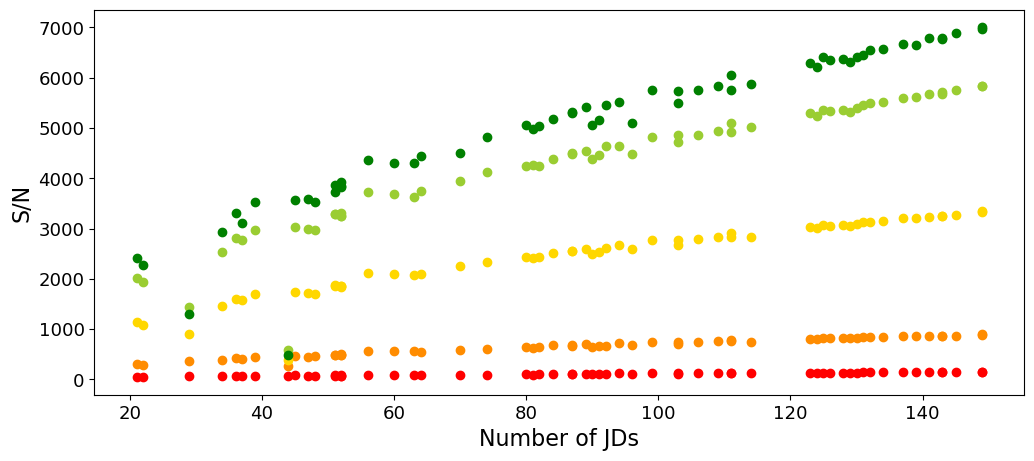

In [23]:
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
NEID_starting_idx=9
NEID_s_values=[]
EXPRES_s_values=[]
orders=[2,12,32,52,72]
colors=['red','darkorange','gold','yellowgreen','green']
for order in orders:
    for i,idx in enumerate(neid_indices):

        w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
        s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
        e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

        w_EXPRES=np.array(data['EXPRES']['wls'][idx])
        s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
        e_EXPRES=np.array(data['EXPRES']['uncs'][idx])

        expres_date_sets = data['EXPRES']['date_sets'][idx]

        jds=np.array(list(expres_date_sets['jds']))
        #get the median jd
        median_jd = np.median(jds)
        #get the number of jds
        num_jds = len(jds)

        sn_EXPRES = s_EXPRES / e_EXPRES

        sn=np.nanpercentile(sn_EXPRES[order],95)
        

        plt.scatter(num_jds, sn, color=colors[orders.index(order)])
plt.xlabel('Number of JDs')
plt.ylabel('S/N')
plt.show()

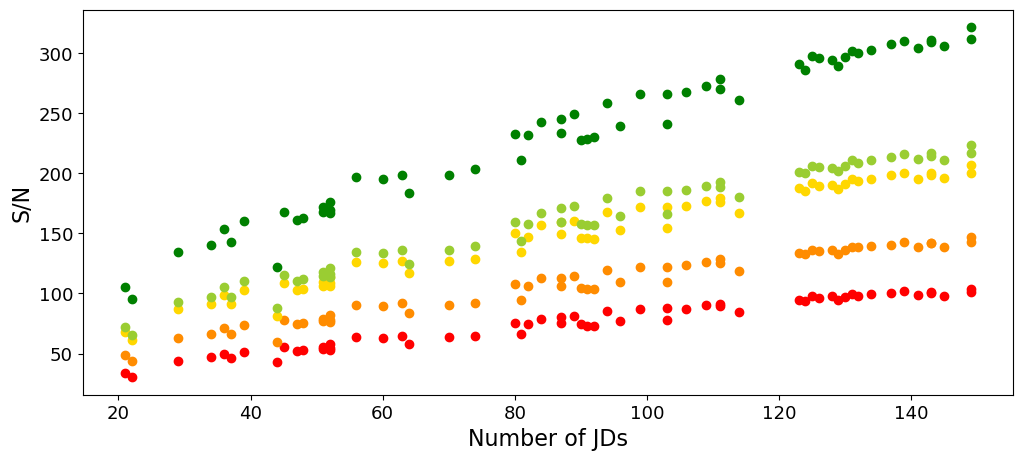

In [24]:
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
NEID_starting_idx=9
NEID_s_values=[]
EXPRES_s_values=[]
orders=[1,2,3,4,5]
colors=['red','darkorange','gold','yellowgreen','green']
for order in orders:
    for i,idx in enumerate(neid_indices):

        w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
        s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
        e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

        w_EXPRES=np.array(data['EXPRES']['wls'][idx])
        s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
        e_EXPRES=np.array(data['EXPRES']['uncs'][idx])

        expres_date_sets = data['EXPRES']['date_sets'][idx]

        jds=np.array(list(expres_date_sets['jds']))
        #get the median jd
        median_jd = np.median(jds)
        #get the number of jds
        num_jds = len(jds)

        sn_EXPRES = s_EXPRES / e_EXPRES

        sn=np.nanpercentile(sn_EXPRES[order],95)
        

        plt.scatter(num_jds, sn, color=colors[orders.index(order)])
plt.xlabel('Number of JDs')
plt.ylabel('S/N')
plt.show()

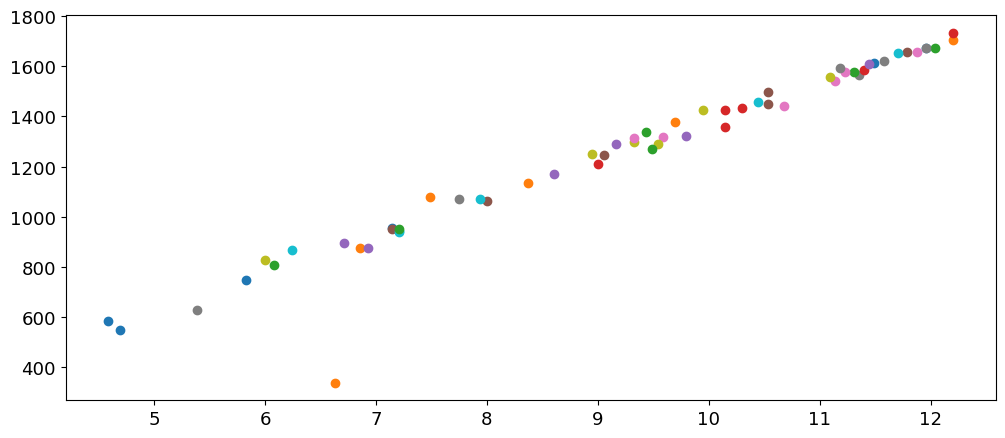

In [62]:
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
NEID_starting_idx=9
NEID_s_values=[]
EXPRES_s_values=[]
order=20
for i,idx in enumerate(neid_indices):

    w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
    s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
    e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])

    expres_date_sets = data['EXPRES']['date_sets'][idx]

    jds=np.array(list(expres_date_sets['jds']))
    #get the median jd
    median_jd = np.median(jds)
    #get the number of jds
    num_jds = len(jds)

    sn_EXPRES = s_EXPRES / e_EXPRES

    sn=np.nanpercentile(sn_EXPRES[order],95)
    

    plt.scatter(np.sqrt(num_jds), sn)

now doing index 0 with NEID index 0000 and EXPRES index 0000
now doing index 1 with NEID index 0001 and EXPRES index 0001
now doing index 2 with NEID index 0002 and EXPRES index 0002
now doing index 3 with NEID index 0003 and EXPRES index 0003
now doing index 4 with NEID index 0004 and EXPRES index 0004
now doing index 5 with NEID index 0005 and EXPRES index 0005
now doing index 6 with NEID index 0006 and EXPRES index 0006
now doing index 7 with NEID index 0007 and EXPRES index 0007
now doing index 8 with NEID index 0008 and EXPRES index 0008
now doing index 9 with NEID index 0009 and EXPRES index 0009
now doing index 10 with NEID index 0010 and EXPRES index 0010
now doing index 11 with NEID index 0011 and EXPRES index 0011
now doing index 12 with NEID index 0012 and EXPRES index 0012
now doing index 13 with NEID index 0013 and EXPRES index 0013
now doing index 14 with NEID index 0014 and EXPRES index 0014
now doing index 15 with NEID index 0015 and EXPRES index 0015
now doing index 16

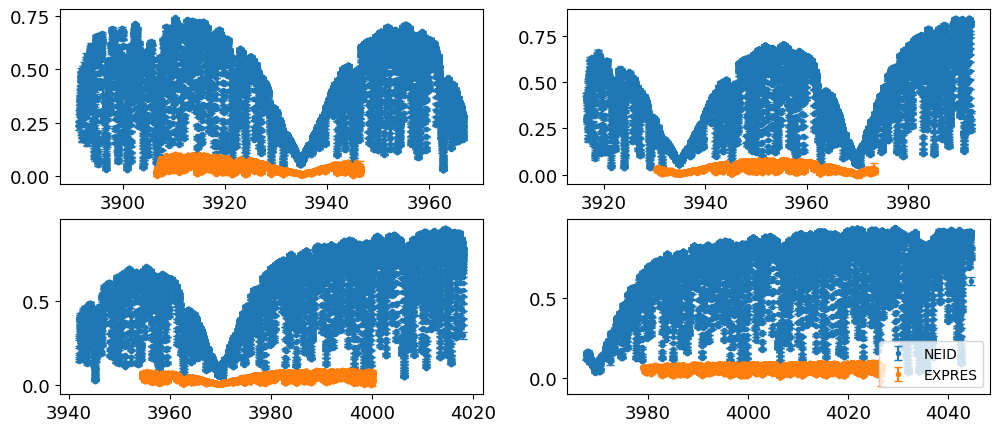

In [56]:
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
NEID_starting_idx=9
NEID_s_values=[]
EXPRES_s_values=[]
NEID_s_values_unc=[]    
EXPRES_s_values_unc=[]    
for i,idx in enumerate(neid_indices):
    print('now doing index', i, 'with NEID index', idx, 'and EXPRES index', idx)

    #check to make sure the data exists and the shape is not (0,)
    if data['NEID']['wls'][idx][NEID_starting_idx:].shape == (0,) or data['NEID']['coadds'][idx][NEID_starting_idx:].shape == (0,) or data['NEID']['uncs'][idx][NEID_starting_idx:].shape == (0,):
        continue
    if data['EXPRES']['wls'][idx].shape == (0,) or data['EXPRES']['coadds'][idx].shape == (0,) or data['EXPRES']['uncs'][idx].shape == (0,):
        continue

    w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
    s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
    e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])

    if i==2:
        for j in range(4):
            plt.subplot(2,2,j+1)
        
            plt.errorbar(w_NEID[j+4],s_NEID[j+4],yerr=e_NEID[j+4],fmt='.',label='NEID')
            plt.errorbar(w_EXPRES[j+4],s_EXPRES[j+4],yerr=e_EXPRES[j+4],fmt='.',label='EXPRES')
        plt.legend()
    
    sval_NEID=svalue.calc_s_value(w_NEID,s_NEID,e_NEID)
    NEID_s_values.append(sval_NEID)

    sval_EXPRES=svalue.calc_s_value(w_EXPRES,s_EXPRES,e_EXPRES)
    EXPRES_s_values.append(sval_EXPRES)

    #do a MC to estimate uncertainties
    NEID_s_values_unc.append(np.std([svalue.calc_s_value(w_NEID,np.random.normal(loc=s_NEID,scale=e_NEID),e_NEID) for _ in range(100)]))
    EXPRES_s_values_unc.append(np.std([svalue.calc_s_value(w_EXPRES,np.random.normal(loc=s_EXPRES,scale=e_EXPRES),e_EXPRES) for _ in range(100)]))
    
#convert both to numpy arrays
NEID_s_values = np.array(NEID_s_values)
EXPRES_s_values = np.array(EXPRES_s_values)
NEID_s_values_unc = np.array(NEID_s_values_unc)
EXPRES_s_values_unc = np.array(EXPRES_s_values_unc)

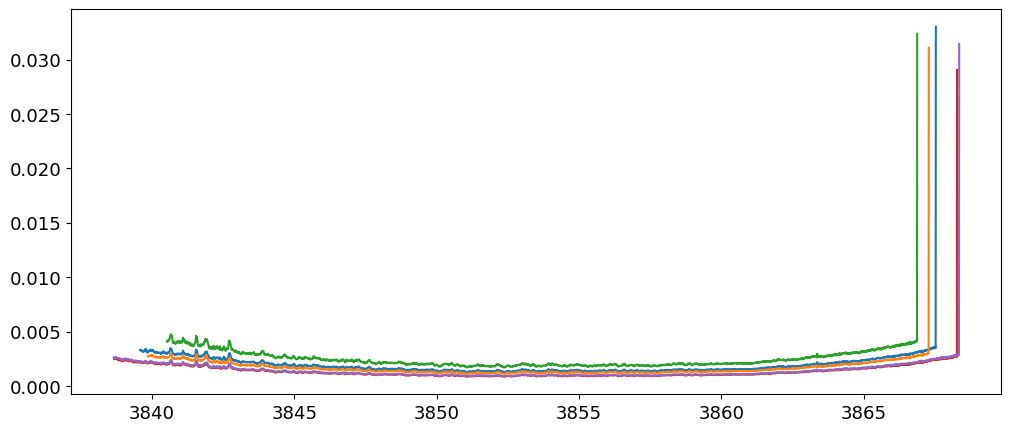

In [15]:
for i,idx in enumerate(neid_indices[:5]):

    w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
    s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
    e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])

    plt.plot(w_EXPRES[1],e_EXPRES[1])

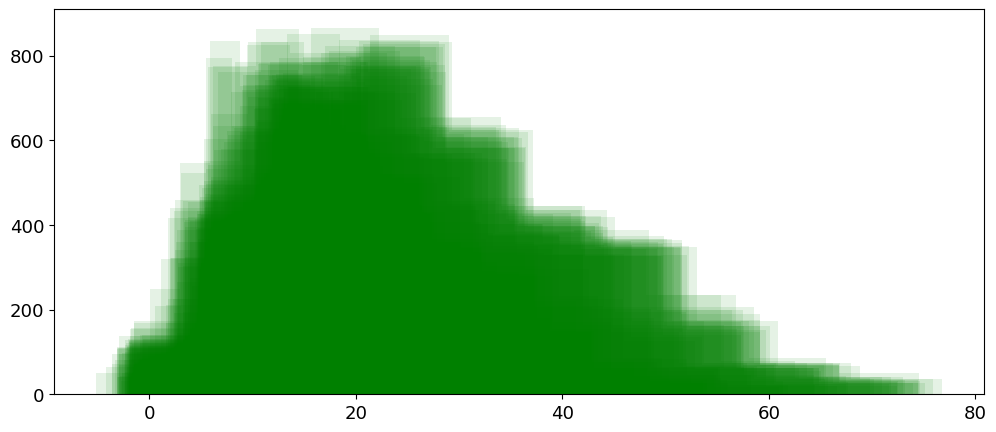

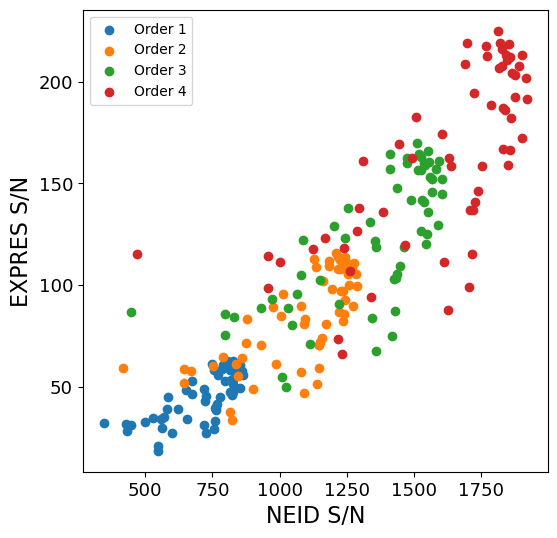

In [21]:
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
NEID_starting_idx=9
NEID_s2n=[]
EXPRES_s2n=[]
for i,idx in enumerate(neid_indices):

    w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
    s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
    e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])
    #print(e_EXPRES)

    N_s2n=[]
    E_s2n=[]
    for j in range(4):
        #calculate the s2n for the first 4 orders
        N_s_o=s_NEID[j]/e_NEID[j]
        E_s_o=s_EXPRES[j]/e_EXPRES[j]
        #print(f"Order {j+1} NEID s2n: {N_s_o}, EXPRES s2n: {E_s_o}")
        #take the 98th percentile of the s2n for this order
        N_s2n.append(np.nanpercentile(N_s_o,98))
        E_s2n.append(np.nanpercentile(E_s_o,98))
        if j==0:
            plt.hist(E_s_o,alpha=.1,color='green')
        

    NEID_s2n.append(N_s2n)
    EXPRES_s2n.append(E_s2n)
#convert both to numpy arrays
NEID_s2n = np.array(NEID_s2n)
EXPRES_s2n = np.array(EXPRES_s2n)

NEID_s2n_t=np.transpose(NEID_s2n)
EXPRES_s2n_t=np.transpose(EXPRES_s2n)
#make the plot a square
plt.figure(figsize=(6,6))
for j in range(NEID_s2n_t.shape[0]):
    plt.scatter(NEID_s2n_t[j],EXPRES_s2n_t[j],label=f'Order {j+1}')
plt.xlabel('NEID S/N')
plt.ylabel('EXPRES S/N')
plt.legend()


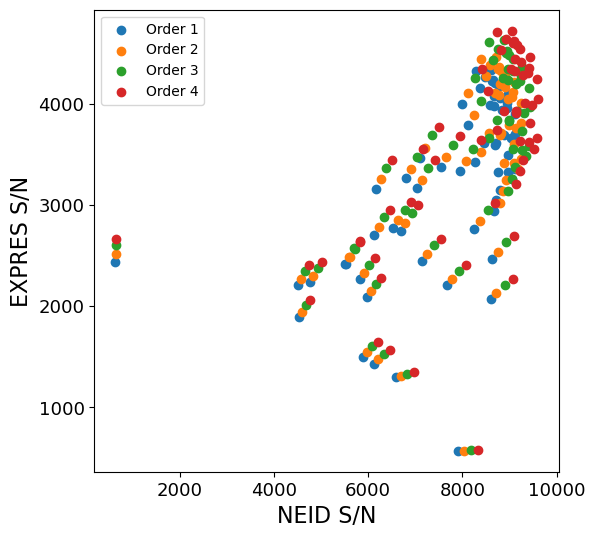

In [48]:
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
NEID_starting_idx=9
NEID_s2n=[]
EXPRES_s2n=[]
for i,idx in enumerate(neid_indices):

    w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
    s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
    e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])
    #print(e_EXPRES)

    N_s2n=[]
    E_s2n=[]
    for j in (np.arange(4)+39):
        #calculate the s2n for the first 4 orders
        N_s_o=s_NEID[j]/e_NEID[j]
        E_s_o=s_EXPRES[j]/e_EXPRES[j]
        #print(f"Order {j+1} NEID s2n: {N_s_o}, EXPRES s2n: {E_s_o}")
        #take the 98th percentile of the s2n for this order
        N_s2n.append(np.nanpercentile(N_s_o,98))
        E_s2n.append(np.nanpercentile(E_s_o,98))
        if j==0:
            plt.hist(E_s_o,alpha=.1,color='green')
        

    NEID_s2n.append(N_s2n)
    EXPRES_s2n.append(E_s2n)
#convert both to numpy arrays
NEID_s2n = np.array(NEID_s2n)
EXPRES_s2n = np.array(EXPRES_s2n)

NEID_s2n_t=np.transpose(NEID_s2n)
EXPRES_s2n_t=np.transpose(EXPRES_s2n)
#make the plot a square
plt.figure(figsize=(6,6))
for j in range(NEID_s2n_t.shape[0]):
    plt.scatter(NEID_s2n_t[j],EXPRES_s2n_t[j],label=f'Order {j+1}')
plt.xlabel('NEID S/N')
plt.ylabel('EXPRES S/N')
plt.legend()


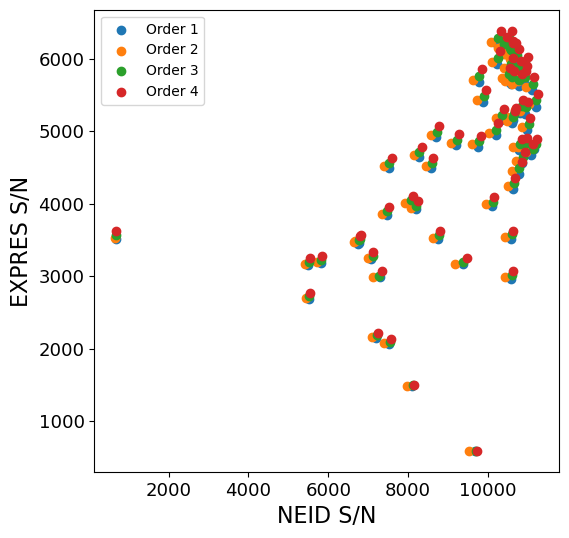

In [49]:
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
NEID_starting_idx=9
NEID_s2n=[]
EXPRES_s2n=[]
for i,idx in enumerate(neid_indices):

    w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
    s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
    e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])
    #print(e_EXPRES)

    N_s2n=[]
    E_s2n=[]
    for j in (np.arange(4)+55):
        #calculate the s2n for the first 4 orders
        N_s_o=s_NEID[j]/e_NEID[j]
        E_s_o=s_EXPRES[j]/e_EXPRES[j]
        #print(f"Order {j+1} NEID s2n: {N_s_o}, EXPRES s2n: {E_s_o}")
        #take the 98th percentile of the s2n for this order
        N_s2n.append(np.nanpercentile(N_s_o,98))
        E_s2n.append(np.nanpercentile(E_s_o,98))
        if j==0:
            plt.hist(E_s_o,alpha=.1,color='green')
        

    NEID_s2n.append(N_s2n)
    EXPRES_s2n.append(E_s2n)
#convert both to numpy arrays
NEID_s2n = np.array(NEID_s2n)
EXPRES_s2n = np.array(EXPRES_s2n)

NEID_s2n_t=np.transpose(NEID_s2n)
EXPRES_s2n_t=np.transpose(EXPRES_s2n)
#make the plot a square
plt.figure(figsize=(6,6))
for j in range(NEID_s2n_t.shape[0]):
    plt.scatter(NEID_s2n_t[j],EXPRES_s2n_t[j],label=f'Order {j+1}')
plt.xlabel('NEID S/N')
plt.ylabel('EXPRES S/N')
plt.legend()


Correlation coefficient: -0.00582094918726053


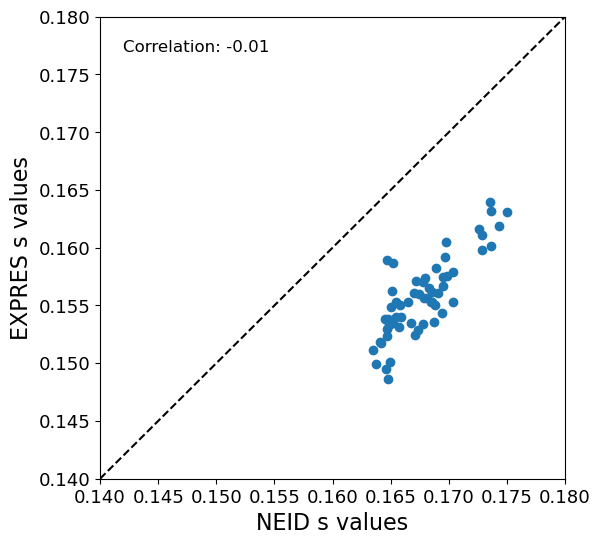

In [59]:
plot_min=.14
plot_max=.18

plt.figure(figsize=(6,6))
plt.scatter(NEID_s_values, EXPRES_s_values)
plt.xlabel('NEID s values')
plt.ylabel('EXPRES s values')
plt.xlim(plot_min,plot_max)
plt.ylim(plot_min,plot_max)
plt.plot([plot_min,plot_max],[plot_min,plot_max],'k--')

#calculate correlation coefficient
cor = np.corrcoef(NEID_s_values, EXPRES_s_values)[0,1]
#write it on the plot
plt.text(plot_min+.002, plot_max-.002, f"Correlation: {cor:.2f}", fontsize=12, verticalalignment='top')
print("Correlation coefficient:", cor)

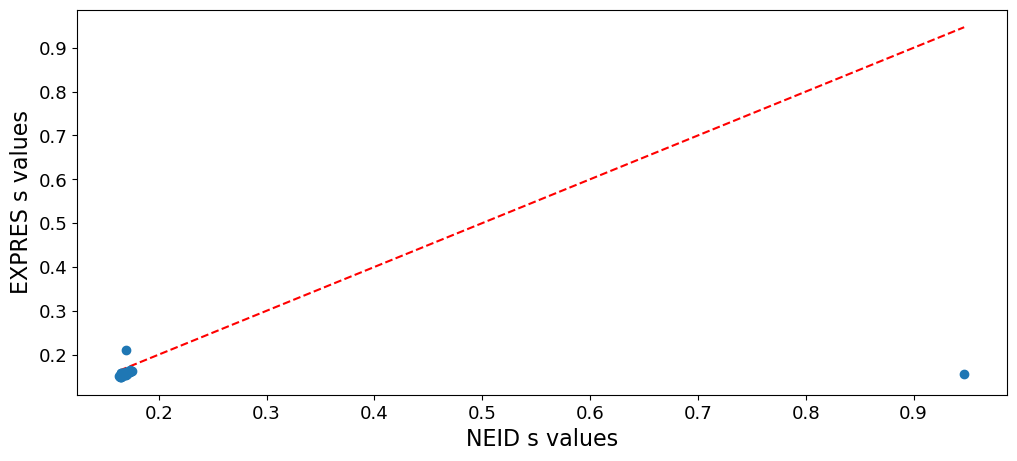

In [60]:
plt.errorbar(NEID_s_values, EXPRES_s_values, xerr=NEID_s_values_unc, yerr=EXPRES_s_values_unc, fmt='o')
plt.xlabel('NEID s values')
plt.ylabel('EXPRES s values')
plt.plot([min(NEID_s_values), max(NEID_s_values)], [min(NEID_s_values), max(NEID_s_values)], 'r--')


Correlation coefficient: 0.8260912617114394


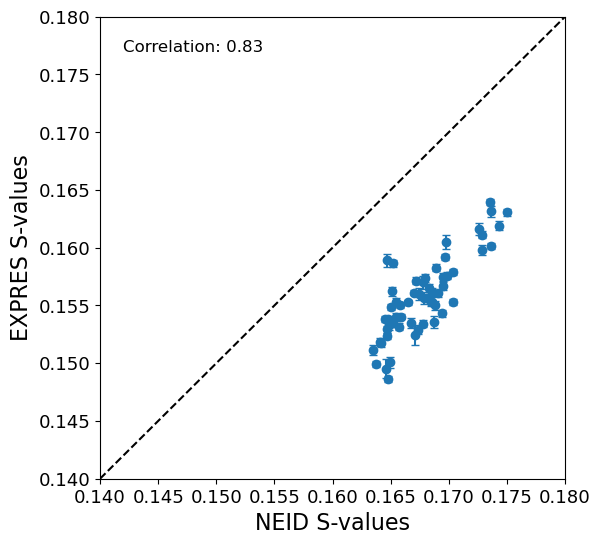

In [61]:
plot_min=.14
plot_max=.18

#good vals is where both are between .1 and .2  
good_vals = (NEID_s_values > .1) & (NEID_s_values < .2) & (EXPRES_s_values > .1) & (EXPRES_s_values < .2)


plt.figure(figsize=(6,6))
plt.errorbar(NEID_s_values[good_vals], EXPRES_s_values[good_vals], xerr=NEID_s_values_unc[good_vals], yerr=EXPRES_s_values_unc[good_vals], fmt='o')
plt.xlabel('NEID S-values')
plt.ylabel('EXPRES S-values')
plt.xlim(plot_min,plot_max)
plt.ylim(plot_min,plot_max)
plt.plot([plot_min,plot_max],[plot_min,plot_max],'k--')

#calculate correlation coefficient
cor = np.corrcoef(NEID_s_values[good_vals], EXPRES_s_values[good_vals])[0,1]
#write it on the plot
plt.text(plot_min+.002, plot_max-.002, f"Correlation: {cor:.2f}", fontsize=12, verticalalignment='top')
print("Correlation coefficient:", cor)

In [20]:
def find_closest_order(central_wavelength,spectrograph):
    if spectrograph == 'NEID':
        wl_centers = order_centers['NEID_wl_center']
    elif spectrograph == 'EXPRES':
        wl_centers = order_centers['EXPRES_wl_center']
    
    distances = np.abs(wl_centers - central_wavelength)
    closest_order_idx = np.argmin(distances)
    
    return order_centers['order'][closest_order_idx]

In [21]:
find_closest_order(3901,'EXPRES')

np.int64(3)

In [ ]:
#save fit results to pickele file

#with open('aaa','wb') as f:
#    pickle.dump(fit_results,f)